# 🧱 Dia 7 — Programação Orientada a Objetos (POO) para Data Science

**Fase 1 — Python Basics** · Data: 2026-10-20 · Autor: Gutemberg Rapôso

Até aqui trabalhamos com funções, pandas, NumPy e regex. Hoje damos um passo decisivo rumo ao código
de nível profissional: **organizar lógica de dados em classes**. Toda biblioteca que usamos
(pandas, scikit-learn, PyTorch) é construída sobre POO — entender esse paradigma é o que separa
*scripts* de *sistemas*.

### 🎯 Objetivos de aprendizado
1. Criar classes com `__init__`, `__repr__` e `__str__` e aplicar **encapsulamento** com `@property`.
2. Usar **herança** e **polimorfismo** para construir uma família de processadores de dados (`fit`/`transform`).
3. Modelar configurações de experimentos com **`@dataclass`** (`frozen=True`, `field()`).
4. Implementar um **transformer customizado compatível com scikit-learn** (`BaseEstimator`, `TransformerMixin`).
5. Aplicar **composição em vez de herança** para montar um pipeline de PLN.
6. Analisar a **legibilidade (Flesch Reading Ease)** de textos clássicos de domínio público.

### 📦 Dados utilizados (somente dados reais)
- `seaborn.load_dataset('titanic')` — passageiros reais do Titanic.
- Trechos de **obras clássicas em inglês de domínio público** (Austen, Dickens, Carroll, Potter, Lincoln etc.),
  amplamente utilizados em materiais didáticos de língua inglesa.

In [1]:
# Core imports used throughout the notebook
import re
import math
from dataclasses import dataclass, field, asdict, replace, FrozenInstanceError
from typing import List, Dict, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 60)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.2.3 | numpy 1.26.4


### 📚 Corpus de textos reais (domínio público)

Abaixo, um pequeno corpus com trechos **literais** de obras clássicas em inglês, todas em domínio público.
Esses textos aparecem com frequência em livros didáticos e *readers* graduados de inglês — de contos
infantis (Beatrix Potter) a prosa vitoriana complexa (Dickens). Isso nos dá um gradiente natural de
dificuldade para testar métricas de legibilidade.

In [2]:
# Public-domain excerpts (verbatim openings/passages of classic English texts)
CORPUS: List[Dict[str, str]] = [
    {
        "title": "The Tale of Peter Rabbit",
        "author": "Beatrix Potter (1902)",
        "text": (
            "Once upon a time there were four little Rabbits, and their names were Flopsy, "
            "Mopsy, Cotton-tail, and Peter. They lived with their Mother in a sand-bank, "
            "underneath the root of a very big fir-tree."
        ),
    },
    {
        "title": "Alice's Adventures in Wonderland",
        "author": "Lewis Carroll (1865)",
        "text": (
            "Alice was beginning to get very tired of sitting by her sister on the bank, and of "
            "having nothing to do: once or twice she had peeped into the book her sister was "
            "reading, but it had no pictures or conversations in it, 'and what is the use of a "
            "book,' thought Alice 'without pictures or conversations?'"
        ),
    },
    {
        "title": "Pride and Prejudice",
        "author": "Jane Austen (1813)",
        "text": (
            "It is a truth universally acknowledged, that a single man in possession of a good "
            "fortune, must be in want of a wife. However little known the feelings or views of "
            "such a man may be on his first entering a neighbourhood, this truth is so well fixed "
            "in the minds of the surrounding families, that he is considered the rightful property "
            "of some one or other of their daughters."
        ),
    },
    {
        "title": "A Tale of Two Cities",
        "author": "Charles Dickens (1859)",
        "text": (
            "It was the best of times, it was the worst of times, it was the age of wisdom, it was "
            "the age of foolishness, it was the epoch of belief, it was the epoch of incredulity, "
            "it was the season of Light, it was the season of Darkness, it was the spring of hope, "
            "it was the winter of despair."
        ),
    },
    {
        "title": "Moby-Dick",
        "author": "Herman Melville (1851)",
        "text": (
            "Call me Ishmael. Some years ago - never mind how long precisely - having little or no "
            "money in my purse, and nothing particular to interest me on shore, I thought I would "
            "sail about a little and see the watery part of the world."
        ),
    },
    {
        "title": "Gettysburg Address",
        "author": "Abraham Lincoln (1863)",
        "text": (
            "Four score and seven years ago our fathers brought forth on this continent, a new "
            "nation, conceived in Liberty, and dedicated to the proposition that all men are "
            "created equal. Now we are engaged in a great civil war, testing whether that nation, "
            "or any nation so conceived and so dedicated, can long endure."
        ),
    },
    {
        "title": "Declaration of Independence",
        "author": "Thomas Jefferson et al. (1776)",
        "text": (
            "We hold these truths to be self-evident, that all men are created equal, that they "
            "are endowed by their Creator with certain unalienable Rights, that among these are "
            "Life, Liberty and the pursuit of Happiness."
        ),
    },
    {
        "title": "The Adventures of Tom Sawyer",
        "author": "Mark Twain (1876)",
        "text": (
            "\"Tom!\" No answer. \"Tom!\" No answer. \"What's gone with that boy, I wonder? "
            "You TOM!\" No answer."
        ),
    },
]

titles = [d["title"] for d in CORPUS]
texts = [d["text"] for d in CORPUS]
print(f"Corpus size: {len(texts)} documents")
for t in titles:
    print(" -", t)

Corpus size: 8 documents
 - The Tale of Peter Rabbit
 - Alice's Adventures in Wonderland
 - Pride and Prejudice
 - A Tale of Two Cities
 - Moby-Dick
 - Gettysburg Address
 - Declaration of Independence
 - The Adventures of Tom Sawyer


## 1️⃣ Fundamentos de POO para Data Science

Uma **classe** é um molde que agrupa **dados (atributos)** e **comportamento (métodos)**. Em Data Science,
isso permite que um objeto "saiba" coisas sobre si mesmo — por exemplo, um documento que sabe contar
suas palavras e frases.

Métodos especiais (*dunder methods*) importantes:

| Método | Para que serve | Quem chama |
|--------|----------------|-----------|
| `__init__` | Inicializa o objeto | `TextDocument(...)` |
| `__repr__` | Representação **inequívoca**, para desenvolvedores | console, listas, debug |
| `__str__` | Representação **amigável**, para usuários | `print()` |
| `__len__` | Tamanho do objeto | `len(obj)` |

In [3]:
class TextDocument:
    """A lightweight representation of a text document for NLP / education tasks.

    Parameters
    ----------
    text : str
        Raw text content.
    title : str
        Human-readable title.
    author : str, optional
        Author / source information.
    """

    # Class attribute: shared by ALL instances
    word_pattern = re.compile(r"[A-Za-z]+(?:['-][A-Za-z]+)*")

    def __init__(self, text: str, title: str, author: str = "Unknown") -> None:
        self.title = title
        self.author = author
        self._text = text  # leading underscore = "internal" by convention

    def __repr__(self) -> str:
        return f"TextDocument(title={self.title!r}, n_words={self.n_words})"

    def __str__(self) -> str:
        preview = self._text[:50] + ("..." if len(self._text) > 50 else "")
        return f"'{self.title}' by {self.author}: \"{preview}\""

    def __len__(self) -> int:
        return self.n_words

    @property
    def words(self) -> List[str]:
        """List of word tokens (letters, internal apostrophes/hyphens)."""
        return self.word_pattern.findall(self._text)

    @property
    def n_words(self) -> int:
        return len(self.words)

    @property
    def n_sentences(self) -> int:
        """Count sentences by terminal punctuation (at least 1)."""
        return max(1, len(re.findall(r"[.!?]+", self._text)))


doc = TextDocument(**CORPUS[0])
print(doc)          # uses __str__
print(repr(doc))    # uses __repr__
print("len(doc) =", len(doc), "| sentences =", doc.n_sentences)

'The Tale of Peter Rabbit' by Beatrix Potter (1902): "Once upon a time there were four little Rabbits, a..."
TextDocument(title='The Tale of Peter Rabbit', n_words=34)
len(doc) = 34 | sentences = 2


### 🔒 Encapsulamento com `@property` e *setters*

**Encapsular** é proteger o estado interno do objeto, expondo-o por uma interface controlada.
Em Python não há `private` verdadeiro: usamos a convenção `_atributo` + `@property`.

Vantagens práticas em DS:
- **Validação** na atribuição (ex.: texto não pode ser vazio).
- **Atributos derivados** calculados sob demanda (sempre consistentes com os dados).
- **Cache invalidation**: ao alterar o texto, estatísticas são recalculadas automaticamente.

In [4]:
class ValidatedTextDocument(TextDocument):
    """TextDocument with a validated, mutable `text` property."""

    @property
    def text(self) -> str:
        """Read access to the raw text."""
        return self._text

    @text.setter
    def text(self, value: str) -> None:
        """Validate before assigning: must be a non-empty string."""
        if not isinstance(value, str):
            raise TypeError(f"text must be str, got {type(value).__name__}")
        if not value.strip():
            raise ValueError("text cannot be empty or whitespace")
        self._text = value.strip()


vdoc = ValidatedTextDocument(**CORPUS[4])
print("Before:", repr(vdoc))

vdoc.text = "Call me Ishmael."          # valid -> derived stats update automatically
print("After :", repr(vdoc))

for bad in ["   ", 42]:
    try:
        vdoc.text = bad
    except (TypeError, ValueError) as err:
        print(f"Rejected {bad!r}: {type(err).__name__} -> {err}")

Before: TextDocument(title='Moby-Dick', n_words=43)
After : TextDocument(title='Moby-Dick', n_words=3)
Rejected '   ': ValueError -> text cannot be empty or whitespace
Rejected 42: TypeError -> text must be str, got int


> 💡 **Dica prática:** `n_words` e `n_sentences` são *properties* sem setter — ou seja, **somente leitura**.
> Tentar `doc.n_words = 10` gera `AttributeError`. Isso impede que estatísticas fiquem inconsistentes
> com o texto, um bug muito comum em notebooks com variáveis soltas.

In [5]:
try:
    vdoc.n_words = 10
except AttributeError as err:
    print("AttributeError:", err)

# Build a collection of documents from the real corpus
documents = [TextDocument(**d) for d in CORPUS]
documents  # list display uses __repr__

AttributeError: property 'n_words' of 'ValidatedTextDocument' object has no setter


[TextDocument(title='The Tale of Peter Rabbit', n_words=34),
 TextDocument(title="Alice's Adventures in Wonderland", n_words=57),
 TextDocument(title='Pride and Prejudice', n_words=70),
 TextDocument(title='A Tale of Two Cities', n_words=60),
 TextDocument(title='Moby-Dick', n_words=43),
 TextDocument(title='Gettysburg Address', n_words=54),
 TextDocument(title='Declaration of Independence', n_words=35),
 TextDocument(title='The Adventures of Tom Sawyer', n_words=17)]

## 2️⃣ Herança e Polimorfismo

**Herança** permite que uma subclasse reaproveite e especialize o comportamento de uma classe base.
**Polimorfismo** significa que objetos diferentes respondem à **mesma interface** (`fit`, `transform`)
cada um à sua maneira — e o código cliente não precisa saber qual é qual.

Esse é exatamente o padrão do scikit-learn: `StandardScaler`, `TfidfVectorizer` e `PCA` têm classes
totalmente diferentes, mas todos expõem `fit()` e `transform()`.

Usaremos `abc.ABC` para declarar uma **classe base abstrata**: ela define o *contrato* e não pode ser
instanciada diretamente.

In [6]:
from abc import ABC, abstractmethod


class DataProcessor(ABC):
    """Abstract base class defining the fit/transform contract."""

    def __init__(self, name: str) -> None:
        self.name = name
        self.is_fitted = False

    @abstractmethod
    def fit(self, data):
        """Learn parameters from data. Must return self."""

    @abstractmethod
    def transform(self, data):
        """Apply the learned transformation."""

    def fit_transform(self, data):
        """Shared implementation inherited by every subclass."""
        return self.fit(data).transform(data)

    def _check_fitted(self) -> None:
        if not self.is_fitted:
            raise RuntimeError(f"{self.name} must be fitted before transform().")

    def __repr__(self) -> str:
        return f"{type(self).__name__}(name={self.name!r}, fitted={self.is_fitted})"


try:
    DataProcessor("abstract")
except TypeError as err:
    print("Cannot instantiate ABC:", err)

Cannot instantiate ABC: Can't instantiate abstract class DataProcessor with abstract methods fit, transform


### 🧹 Subclasse 1: `TextCleaner`

Normaliza textos: minúsculas, remoção de pontuação e (opcionalmente) *stopwords*. No `fit`, aprende o
**vocabulário** do corpus — útil para saber quantos tipos (*types*) distintos existem.

In [7]:
class TextCleaner(DataProcessor):
    """Normalize a list of raw texts (lowercase, strip punctuation, drop stopwords)."""

    DEFAULT_STOPWORDS = frozenset(
        "a an the and or but of to in on at by for with is was it that this be are "
        "as from his her their our my me i we they he she you".split()
    )

    def __init__(self, lowercase: bool = True, remove_stopwords: bool = False) -> None:
        super().__init__(name="TextCleaner")   # call parent constructor
        self.lowercase = lowercase
        self.remove_stopwords = remove_stopwords
        self.vocabulary_: set = set()

    def _clean_one(self, text: str) -> str:
        if self.lowercase:
            text = text.lower()
        tokens = re.findall(r"[a-zA-Z]+(?:'[a-zA-Z]+)?", text)
        if self.remove_stopwords:
            tokens = [t for t in tokens if t.lower() not in self.DEFAULT_STOPWORDS]
        return " ".join(tokens)

    def fit(self, data: List[str]) -> "TextCleaner":
        self.vocabulary_ = {tok for t in data for tok in self._clean_one(t).split()}
        self.is_fitted = True
        return self

    def transform(self, data: List[str]) -> List[str]:
        self._check_fitted()
        return [self._clean_one(t) for t in data]


cleaner = TextCleaner(remove_stopwords=True)
cleaned = cleaner.fit_transform(texts)   # fit_transform inherited from DataProcessor
print(cleaner)
print("Vocabulary size:", len(cleaner.vocabulary_))
print("Original:", texts[0][:70])
print("Cleaned :", cleaned[0][:70])

TextCleaner(name='TextCleaner', fitted=True)
Vocabulary size: 162
Original: Once upon a time there were four little Rabbits, and their names were 
Cleaned : once upon time there were four little rabbits names were flopsy mopsy 


### 📏 Subclasse 2: `NumericalScaler` (dataset Titanic)

Padronização *z-score*: $z = \frac{x - \mu}{\sigma}$. Os parâmetros $\mu$ e $\sigma$ são aprendidos
no `fit` e reaplicados no `transform` — o mesmo princípio que evita **data leakage** entre treino e teste.

In [8]:
class NumericalScaler(DataProcessor):
    """Z-score standardization for numeric DataFrame columns (NaN-aware)."""

    def __init__(self, columns: Optional[List[str]] = None) -> None:
        super().__init__(name="NumericalScaler")
        self.columns = columns
        self.means_: Optional[pd.Series] = None
        self.stds_: Optional[pd.Series] = None

    def fit(self, data: pd.DataFrame) -> "NumericalScaler":
        cols = self.columns or data.select_dtypes("number").columns.tolist()
        self.columns = cols
        self.means_ = data[cols].mean()
        self.stds_ = data[cols].std(ddof=0).replace(0, 1.0)  # avoid division by zero
        self.is_fitted = True
        return self

    def transform(self, data: pd.DataFrame) -> pd.DataFrame:
        self._check_fitted()
        out = data.copy()
        out[self.columns] = (data[self.columns] - self.means_) / self.stds_
        return out


titanic = sns.load_dataset("titanic")
num_cols = ["age", "fare", "sibsp", "parch"]
print("Titanic shape:", titanic.shape)
titanic[num_cols].describe().round(2)

Titanic shape: (891, 15)


,age,fare,sibsp,parch
count,714.00,891.00,891.00,891.00
mean,29.70,32.20,0.52,0.38
std,14.53,49.69,1.10,0.81
min,0.42,0.00,0.00,0.00
25%,20.12,7.91,0.00,0.00
50%,28.00,14.45,0.00,0.00
75%,38.00,31.00,1.00,0.00
max,80.00,512.33,8.00,6.00


In [9]:
scaler = NumericalScaler(columns=num_cols)
titanic_scaled = scaler.fit_transform(titanic)

summary = pd.DataFrame({
    "learned_mean": scaler.means_.round(2),
    "learned_std": scaler.stds_.round(2),
    "scaled_mean": titanic_scaled[num_cols].mean().round(4),
    "scaled_std": titanic_scaled[num_cols].std(ddof=0).round(4),
})
summary

,learned_mean,learned_std,scaled_mean,scaled_std
age,29.70,14.52,0.0,1.0
fare,32.20,49.67,0.0,1.0
sibsp,0.52,1.10,0.0,1.0
parch,0.38,0.81,0.0,1.0


In [10]:
# Sanity check: our scaler must match sklearn's StandardScaler on non-missing rows
complete = titanic[num_cols].dropna()
ours = NumericalScaler(columns=num_cols).fit_transform(complete)[num_cols].to_numpy()
sk = StandardScaler().fit_transform(complete)
print("Matches sklearn StandardScaler:", np.allclose(ours, sk))

Matches sklearn StandardScaler: True


### 🎭 Polimorfismo em ação

A função abaixo **não sabe** se recebe um `TextCleaner` ou um `NumericalScaler` — ela só confia no
contrato `fit_transform`. Isso é *duck typing* com garantia formal da classe abstrata.

In [11]:
def run_processor(processor: DataProcessor, data) -> None:
    """Generic client code: works with ANY DataProcessor subclass."""
    result = processor.fit_transform(data)
    kind = type(result).__name__
    size = len(result)
    print(f"{processor!r:<45} -> output type={kind:<10} size={size}")


for proc, data in [(TextCleaner(), texts), (NumericalScaler(num_cols), titanic)]:
    run_processor(proc, data)

print("\nIs TextCleaner a DataProcessor?", issubclass(TextCleaner, DataProcessor))
print("MRO:", [c.__name__ for c in NumericalScaler.__mro__])

TextCleaner(name='TextCleaner', fitted=True)  -> output type=list       size=8
NumericalScaler(name='NumericalScaler', fitted=True) -> output type=DataFrame  size=891

Is TextCleaner a DataProcessor? True
MRO: ['NumericalScaler', 'DataProcessor', 'ABC', 'object']


## 3️⃣ Dataclasses para Configuração de Experimentos

Experimentos de ML dependem de dezenas de hiperparâmetros. Guardá-los em dicionários soltos leva a
erros de digitação silenciosos (`"learning_rte"`). O decorator **`@dataclass`** gera automaticamente
`__init__`, `__repr__` e `__eq__` a partir de *type hints*.

| Recurso | Efeito |
|---------|--------|
| `frozen=True` | Objeto **imutável** (e *hashable*) — ideal para configs reprodutíveis |
| `field(default_factory=list)` | Default mutável seguro (nunca use `= []`!) |
| `__post_init__` | Validação após a construção |
| `asdict()` / `replace()` | Serializar para dict / criar cópia modificada |

In [12]:
@dataclass(frozen=True)
class ModelConfig:
    """Immutable hyperparameter configuration for a model."""

    model_name: str
    learning_rate: float = 0.01
    max_depth: Optional[int] = None
    random_state: int = 42

    def __post_init__(self) -> None:
        if not 0 < self.learning_rate <= 1:
            raise ValueError(f"learning_rate must be in (0, 1], got {self.learning_rate}")


cfg = ModelConfig("gradient_boosting", learning_rate=0.1, max_depth=3)
print(cfg)
print("Equal to identical config?", cfg == ModelConfig("gradient_boosting", 0.1, 3))
print("Hashable (usable as dict key):", hash(cfg) is not None)

try:
    cfg.learning_rate = 0.5
except FrozenInstanceError as err:
    print("FrozenInstanceError:", err)

try:
    ModelConfig("bad", learning_rate=5)
except ValueError as err:
    print("ValueError:", err)

ModelConfig(model_name='gradient_boosting', learning_rate=0.1, max_depth=3, random_state=42)
Equal to identical config? True
Hashable (usable as dict key): True
FrozenInstanceError: cannot assign to field 'learning_rate'
ValueError: learning_rate must be in (0, 1], got 5


In [13]:
@dataclass
class ExperimentConfig:
    """Mutable experiment description that composes a frozen ModelConfig."""

    name: str
    model: ModelConfig
    dataset: str = "titanic"
    features: List[str] = field(default_factory=lambda: ["age", "fare", "sibsp", "parch"])
    target: str = "survived"
    test_size: float = 0.2
    tags: List[str] = field(default_factory=list)
    notes: str = field(default="", repr=False)   # hidden from repr

    @property
    def n_features(self) -> int:
        return len(self.features)


exp = ExperimentConfig(name="baseline_v1", model=cfg, tags=["phase1", "oop"])
print(exp)
print("n_features:", exp.n_features)

# Safe mutable defaults: each instance gets its OWN list
exp2 = ExperimentConfig(name="baseline_v2", model=cfg)
exp2.tags.append("ablation")
print("exp.tags :", exp.tags, "| exp2.tags:", exp2.tags)

ExperimentConfig(name='baseline_v1', model=ModelConfig(model_name='gradient_boosting', learning_rate=0.1, max_depth=3, random_state=42), dataset='titanic', features=['age', 'fare', 'sibsp', 'parch'], target='survived', test_size=0.2, tags=['phase1', 'oop'])
n_features: 4
exp.tags : ['phase1', 'oop'] | exp2.tags: ['ablation']


In [14]:
# Grid of configs via replace() -- the original frozen object is never mutated
grid = [replace(cfg, learning_rate=lr) for lr in (0.01, 0.05, 0.1)]
pd.DataFrame([asdict(c) for c in grid])

,model_name,learning_rate,max_depth,random_state
0,gradient_boosting,0.01,3,42
1,gradient_boosting,0.05,3,42
2,gradient_boosting,0.10,3,42


> 💡 **Dica prática:** combine `asdict(config)` com `json.dump` para salvar a configuração exata de cada
> experimento ao lado dos resultados — base para ferramentas como MLflow e Hydra.

## 4️⃣ O Contrato de Estimadores do scikit-learn

Para que uma classe funcione em `Pipeline`, `GridSearchCV` e `clone()`, ela deve seguir regras simples:

1. Herdar de **`BaseEstimator`** → ganha `get_params()` / `set_params()` automaticamente.
2. Herdar de **`TransformerMixin`** → ganha `fit_transform()` de graça.
3. `__init__` **apenas armazena** os hiperparâmetros, com o **mesmo nome** dos argumentos — sem lógica!
4. `fit(X, y=None)` aprende o estado, cria atributos com **sufixo `_`** e **retorna `self`**.
5. `transform(X)` retorna um array/DataFrame com as features.

### 📖 Fórmula de Flesch Reading Ease

$$FRE = 206.835 - 1.015 \left(\frac{\text{palavras}}{\text{frases}}\right) - 84.6 \left(\frac{\text{sílabas}}{\text{palavras}}\right)$$

| FRE | Nível de leitura |
|-----|------------------|
| 90–100 | Muito fácil (≈ 5º ano) |
| 60–70 | Padrão (≈ 8º–9º ano) |
| 30–50 | Difícil (universitário) |
| 0–30 | Muito difícil (pós-graduação) |

Como linguista, vale notar: a contagem de sílabas em inglês por heurística (grupos vocálicos) é uma
**aproximação** — a ortografia inglesa é notoriamente opaca (*"e" mudo*, ditongos etc.).

In [15]:
def count_syllables(word: str) -> int:
    """Heuristic English syllable counter based on vowel groups.

    Rules: count vowel groups (a, e, i, o, u, y), discount a silent final 'e'
    (but keep '-le' as in 'little'), and guarantee at least one syllable.
    """
    word = word.lower().strip("'")
    if not word:
        return 0
    groups = re.findall(r"[aeiouy]+", word)
    n = len(groups)
    if word.endswith("e") and not word.endswith("le") and n > 1:
        n -= 1
    if word.endswith("es") and len(word) > 3 and word[-3] not in "aeiouy" and n > 1 \
            and not re.search(r"(ss|sh|ch|x|z|c|g)es$", word):
        n -= 1
    return max(1, n)


for w in ["cat", "rabbit", "little", "universally", "acknowledged", "make", "conversations"]:
    print(f"{w:<15} -> {count_syllables(w)} syllables")

cat             -> 1 syllables
rabbit          -> 2 syllables
little          -> 2 syllables
universally     -> 5 syllables
acknowledged    -> 4 syllables
make            -> 1 syllables
conversations   -> 4 syllables


In [16]:
class ReadabilityScorer(BaseEstimator, TransformerMixin):
    """Sklearn-compatible transformer computing readability features from raw text.

    Parameters
    ----------
    features : tuple of str
        Which features to output. Any of: 'flesch_reading_ease', 'flesch_kincaid_grade',
        'avg_sentence_length', 'avg_syllables_per_word', 'n_words'.
    as_frame : bool
        If True, `transform` returns a pandas DataFrame; otherwise a NumPy array.
    """

    ALL_FEATURES = (
        "flesch_reading_ease",
        "flesch_kincaid_grade",
        "avg_sentence_length",
        "avg_syllables_per_word",
        "n_words",
    )

    def __init__(self, features=ALL_FEATURES, as_frame: bool = True):
        # Rule 3: only store hyperparameters, no validation/logic here
        self.features = features
        self.as_frame = as_frame

    def fit(self, X, y=None):
        """Validate hyperparameters; stateless otherwise. Returns self."""
        unknown = set(self.features) - set(self.ALL_FEATURES)
        if unknown:
            raise ValueError(f"Unknown features: {sorted(unknown)}")
        self.feature_names_out_ = list(self.features)   # Rule 4: trailing underscore
        self.n_documents_seen_ = len(X)
        return self

    @staticmethod
    def _score_one(text: str) -> Dict[str, float]:
        words = re.findall(r"[A-Za-z]+(?:'[A-Za-z]+)?", text)
        n_words = max(1, len(words))
        n_sent = max(1, len(re.findall(r"[.!?]+", text)))
        n_syll = sum(count_syllables(w) for w in words)
        wps = n_words / n_sent          # words per sentence
        spw = n_syll / n_words          # syllables per word
        return {
            "flesch_reading_ease": 206.835 - 1.015 * wps - 84.6 * spw,
            "flesch_kincaid_grade": 0.39 * wps + 11.8 * spw - 15.59,
            "avg_sentence_length": wps,
            "avg_syllables_per_word": spw,
            "n_words": float(len(words)),
        }

    def transform(self, X):
        if not hasattr(self, "feature_names_out_"):
            raise RuntimeError("ReadabilityScorer is not fitted yet. Call fit() first.")
        rows = [self._score_one(t) for t in X]
        df = pd.DataFrame(rows)[self.feature_names_out_]
        return df if self.as_frame else df.to_numpy()

    def get_feature_names_out(self, input_features=None):
        return np.array(self.feature_names_out_, dtype=object)


scorer = ReadabilityScorer()
print(scorer)                       # repr generated by BaseEstimator
print(scorer.get_params())          # get_params from BaseEstimator

ReadabilityScorer()
{'as_frame': True, 'features': ('flesch_reading_ease', 'flesch_kincaid_grade', 'avg_sentence_length', 'avg_syllables_per_word', 'n_words')}


In [17]:
scores = scorer.fit_transform(texts)    # fit_transform from TransformerMixin
scores.insert(0, "title", titles)
scores.round(2).sort_values("flesch_reading_ease", ascending=False)

,title,flesch_reading_ease,flesch_kincaid_grade,avg_sentence_length,avg_syllables_per_word,n_words
7,The Adventures of Tom Sawyer,99.86,-0.07,2.43,1.24,17.0
0,The Tale of Peter Rabbit,76.02,7.25,18.50,1.32,37.0
4,Moby-Dick,63.03,9.81,21.50,1.44,43.0
2,Pride and Prejudice,48.04,15.25,35.00,1.46,70.0
5,Gettysburg Address,44.70,13.73,27.00,1.59,54.0
6,Declaration of Independence,43.40,16.15,36.00,1.50,36.0
3,A Tale of Two Cities,40.18,22.56,60.00,1.25,60.0
1,Alice's Adventures in Wonderland,30.24,23.20,57.00,1.40,57.0


### 🔍 Verificando a compatibilidade com o ecossistema sklearn

- `clone()` recria o estimador a partir de `get_params()` → prova que o `__init__` segue a regra 3.
- `set_params()` permite que `GridSearchCV` altere hiperparâmetros.
- `Pipeline` encadeia nosso transformer com o `StandardScaler` nativo.

In [18]:
from sklearn.base import clone

cloned = clone(scorer)
print("clone OK:", cloned, "| fitted?", hasattr(cloned, "feature_names_out_"))

scorer_small = clone(scorer).set_params(features=("flesch_reading_ease", "avg_sentence_length"))
print("set_params ->", scorer_small.get_params()["features"])

readability_pipe = Pipeline([
    ("readability", ReadabilityScorer(features=("flesch_reading_ease", "avg_sentence_length",
                                                "avg_syllables_per_word"), as_frame=False)),
    ("scale", StandardScaler()),
])
Z = readability_pipe.fit_transform(texts)
print("\nPipeline output shape:", Z.shape)
print("Feature names:", readability_pipe.named_steps["readability"].get_feature_names_out())
pd.DataFrame(Z, index=titles,
             columns=readability_pipe.named_steps["readability"].get_feature_names_out()).round(2)

clone OK: ReadabilityScorer() | fitted? False
set_params -> ('flesch_reading_ease', 'avg_sentence_length')

Pipeline output shape: (8, 3)
Feature names: ['flesch_reading_ease' 'avg_sentence_length' 'avg_syllables_per_word']


,flesch_reading_ease,avg_sentence_length,avg_syllables_per_word
The Tale of Peter Rabbit,0.95,-0.76,-0.66
Alice's Adventures in Wonderland,-1.19,1.37,0.03
Pride and Prejudice,-0.36,0.16,0.49
A Tale of Two Cities,-0.73,1.54,-1.30
Moby-Dick,0.34,-0.59,0.36
Gettysburg Address,-0.52,-0.29,1.66
Declaration of Independence,-0.58,0.21,0.86
The Adventures of Tom Sawyer,2.07,-1.64,-1.43


In [19]:
try:
    ReadabilityScorer(features=("not_a_feature",)).fit(texts)
except ValueError as err:
    print("Validation in fit():", err)

try:
    ReadabilityScorer().transform(texts)
except RuntimeError as err:
    print("Unfitted transform:", err)

Validation in fit(): Unknown features: ['not_a_feature']
Unfitted transform: ReadabilityScorer is not fitted yet. Call fit() first.


## 5️⃣ Composição em vez de Herança

*"Favor object composition over class inheritance"* — Gang of Four.

Herança modela relações **"é um"** (`TextCleaner` *é um* `DataProcessor`). Composição modela **"tem um"**:
um `NLPPipeline` *tem um* limpador e *tem um* avaliador de legibilidade. Vantagens:

- Componentes **intercambiáveis** (injeção de dependência).
- Evita hierarquias profundas e frágeis.
- Cada classe tem **uma única responsabilidade**.

⚠️ Detalhe linguístico importante: a legibilidade deve ser calculada sobre o **texto original**
(com pontuação, para detectar frases), enquanto o limpador gera a versão normalizada para análise lexical.

In [20]:
class NLPPipeline:
    """Composes a TextCleaner and a ReadabilityScorer into a single analysis object."""

    def __init__(self, cleaner: TextCleaner, scorer: ReadabilityScorer) -> None:
        self.cleaner = cleaner      # "has a" cleaner
        self.scorer = scorer        # "has a" scorer

    def __repr__(self) -> str:
        return f"NLPPipeline(cleaner={self.cleaner!r}, scorer={self.scorer!r})"

    def fit(self, texts: List[str]) -> "NLPPipeline":
        self.cleaner.fit(texts)
        self.scorer.fit(texts)
        return self

    @staticmethod
    def _lexical_stats(cleaned_text: str) -> Dict[str, float]:
        tokens = cleaned_text.split()
        n = len(tokens)
        return {
            "n_content_tokens": n,
            "type_token_ratio": len(set(tokens)) / n if n else 0.0,
            "avg_word_length": float(np.mean([len(t) for t in tokens])) if n else 0.0,
        }

    def analyze(self, texts: List[str], titles: Optional[List[str]] = None) -> pd.DataFrame:
        """Return readability (raw text) + lexical stats (cleaned text) per document."""
        readability = self.scorer.transform(texts)
        if not isinstance(readability, pd.DataFrame):
            readability = pd.DataFrame(readability, columns=self.scorer.get_feature_names_out())
        lexical = pd.DataFrame([self._lexical_stats(c) for c in self.cleaner.transform(texts)])
        result = pd.concat([readability, lexical], axis=1)
        if titles is not None:
            result.insert(0, "title", titles)
        return result


nlp = NLPPipeline(TextCleaner(remove_stopwords=True), ReadabilityScorer()).fit(texts)
print(nlp)
analysis = nlp.analyze(texts, titles)
analysis.round(2)

NLPPipeline(cleaner=TextCleaner(name='TextCleaner', fitted=True), scorer=ReadabilityScorer())


,title,flesch_reading_ease,flesch_kincaid_grade,avg_sentence_length,avg_syllables_per_word,n_words,n_content_tokens,type_token_ratio,avg_word_length
0,The Tale of Peter Rabbit,76.02,7.25,18.50,1.32,37.0,25,0.96,4.80
1,Alice's Adventures in Wonderland,30.24,23.20,57.00,1.40,57.0,31,0.81,5.61
2,Pride and Prejudice,48.04,15.25,35.00,1.46,70.0,36,0.94,6.22
3,A Tale of Two Cities,40.18,22.56,60.00,1.25,60.0,20,0.80,5.85
4,Moby-Dick,63.03,9.81,21.50,1.44,43.0,28,0.96,5.25
5,Gettysburg Address,44.70,13.73,27.00,1.59,54.0,36,0.86,5.56
6,Declaration of Independence,43.40,16.15,36.00,1.50,36.0,20,0.95,5.95
7,The Adventures of Tom Sawyer,99.86,-0.07,2.43,1.24,17.0,13,0.54,4.00


In [21]:
# Swapping a component is trivial with composition (no new subclass needed)
nlp_keep_stop = NLPPipeline(TextCleaner(remove_stopwords=False),
                            ReadabilityScorer(features=("flesch_reading_ease",))).fit(texts)
comparison = pd.DataFrame({
    "title": titles,
    "TTR_without_stopwords": analysis["type_token_ratio"].round(3),
    "TTR_with_stopwords": nlp_keep_stop.analyze(texts)["type_token_ratio"].round(3),
})
comparison

,title,TTR_without_stopwords,TTR_with_stopwords
0,The Tale of Peter Rabbit,0.960,0.865
1,Alice's Adventures in Wonderland,0.806,0.702
2,Pride and Prejudice,0.944,0.686
3,A Tale of Two Cities,0.800,0.333
4,Moby-Dick,0.964,0.884
5,Gettysburg Address,0.861,0.796
6,Declaration of Independence,0.950,0.861
7,The Adventures of Tom Sawyer,0.538,0.647


> 📝 **Nota de aprendizado:** na maioria dos textos a *type-token ratio* (TTR) cai quando mantemos as
> *stopwords*, porque palavras funcionais (*the, of, it, was*) se repetem muito. Dickens é o caso extremo:
> a anáfora *"it was the..."* reduz a diversidade lexical de forma intencional. **Tom Sawyer** é a exceção:
> sem stopwords sobram quase só as repetições *"Tom"* e *"no answer"*, o que derruba a TTR — lembrete de que
> TTR é muito instável em textos curtos.

## 6️⃣ Aplicação Prática: Legibilidade de Textos Clássicos para o Ensino de Inglês

Professores de inglês precisam escolher textos adequados ao nível dos alunos. Vamos usar **todas as
classes criadas** (`TextDocument`, `NLPPipeline`, `ReadabilityScorer`, `ExperimentConfig`) para:

1. Classificar os textos por faixa de dificuldade Flesch.
2. Visualizar a relação entre comprimento de frase, sílabas por palavra e legibilidade.

In [22]:
@dataclass(frozen=True)
class ReadabilityBand:
    """A named Flesch Reading Ease band (inclusive lower bound)."""
    label: str
    min_score: float


BANDS = (
    ReadabilityBand("Very easy", 90), ReadabilityBand("Easy", 80),
    ReadabilityBand("Fairly easy", 70), ReadabilityBand("Standard", 60),
    ReadabilityBand("Fairly difficult", 50), ReadabilityBand("Difficult", 30),
    ReadabilityBand("Very difficult", float("-inf")),
)


def assign_band(score: float) -> str:
    """Map a Flesch score to its band label."""
    return next(b.label for b in BANDS if score >= b.min_score)


report = analysis.copy()
report["author"] = [d.author for d in documents]
report["band"] = report["flesch_reading_ease"].apply(assign_band)
report = report.sort_values("flesch_reading_ease", ascending=False).reset_index(drop=True)
report[["title", "author", "flesch_reading_ease", "flesch_kincaid_grade", "band"]].round(1)

,title,author,flesch_reading_ease,flesch_kincaid_grade,band
0,The Adventures of Tom Sawyer,Mark Twain (1876),99.9,-0.1,Very easy
1,The Tale of Peter Rabbit,Beatrix Potter (1902),76.0,7.3,Fairly easy
2,Moby-Dick,Herman Melville (1851),63.0,9.8,Standard
3,Pride and Prejudice,Jane Austen (1813),48.0,15.3,Difficult
4,Gettysburg Address,Abraham Lincoln (1863),44.7,13.7,Difficult
5,Declaration of Independence,Thomas Jefferson et al. (1776),43.4,16.2,Difficult
6,A Tale of Two Cities,Charles Dickens (1859),40.2,22.6,Difficult
7,Alice's Adventures in Wonderland,Lewis Carroll (1865),30.2,23.2,Difficult


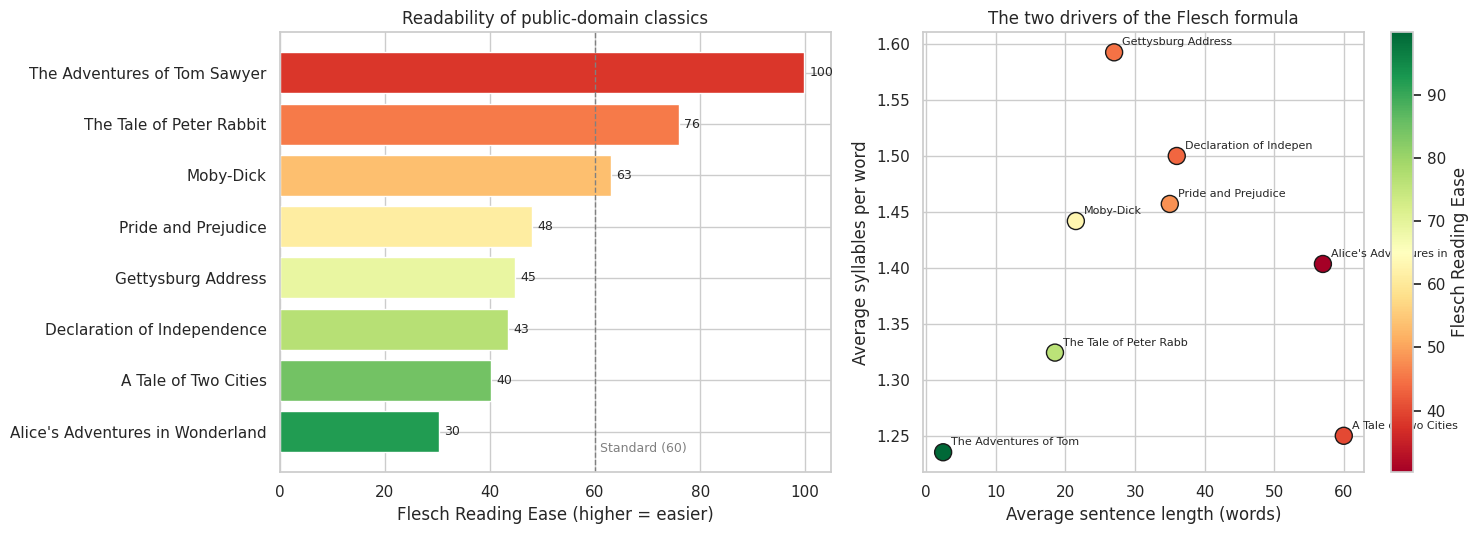

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# (a) Ranked Flesch Reading Ease
palette = sns.color_palette("RdYlGn", n_colors=len(report))[::-1]
ax = axes[0]
ax.barh(report["title"], report["flesch_reading_ease"], color=palette[::-1])
ax.invert_yaxis()
for y, v in enumerate(report["flesch_reading_ease"]):
    ax.text(v + 1, y, f"{v:.0f}", va="center", fontsize=9)
ax.axvline(60, ls="--", c="gray", lw=1)
ax.text(61, len(report) - 0.6, "Standard (60)", color="gray", fontsize=9)
ax.set_xlabel("Flesch Reading Ease (higher = easier)")
ax.set_title("Readability of public-domain classics")

# (b) Sentence length vs. syllables per word, colored by FRE
ax = axes[1]
sc = ax.scatter(report["avg_sentence_length"], report["avg_syllables_per_word"],
                c=report["flesch_reading_ease"], cmap="RdYlGn", s=150, edgecolor="k")
for _, row in report.iterrows():
    ax.annotate(row["title"].split(":")[0][:22],
                (row["avg_sentence_length"], row["avg_syllables_per_word"]),
                textcoords="offset points", xytext=(6, 5), fontsize=8)
ax.set_xlabel("Average sentence length (words)")
ax.set_ylabel("Average syllables per word")
ax.set_title("The two drivers of the Flesch formula")
fig.colorbar(sc, ax=ax, label="Flesch Reading Ease")

plt.tight_layout()
plt.show()

In [24]:
# Which driver matters more in this corpus? Correlation with the final score
drivers = report[["flesch_reading_ease", "avg_sentence_length",
                  "avg_syllables_per_word", "type_token_ratio"]]
drivers.corr()["flesch_reading_ease"].drop("flesch_reading_ease").round(3).to_frame("corr_with_FRE")

,corr_with_FRE
avg_sentence_length,-0.888
avg_syllables_per_word,-0.509
type_token_ratio,-0.473


In [25]:
# Log the analysis as a reproducible experiment using our dataclasses
analysis_exp = ExperimentConfig(
    name="readability_classics_v1",
    model=ModelConfig("flesch_reading_ease", learning_rate=1.0),
    dataset="public_domain_classics",
    features=list(ReadabilityScorer.ALL_FEATURES),
    target="band",
    test_size=0.0,
    tags=["nlp", "education", "readability"],
)
summary_row = {
    "experiment": analysis_exp.name,
    "n_docs": len(texts),
    "n_features": analysis_exp.n_features,
    "easiest": report.iloc[0]["title"],
    "hardest": report.iloc[-1]["title"],
    "fre_range": f'{report["flesch_reading_ease"].min():.1f} – {report["flesch_reading_ease"].max():.1f}',
}
pd.Series(summary_row)

experiment             readability_classics_v1
n_docs                                       8
n_features                                   5
easiest           The Adventures of Tom Sawyer
hardest       Alice's Adventures in Wonderland
fre_range                          30.2 – 99.9
dtype: object

### 🔎 Interpretação

- **Tom Sawyer** (diálogo curtíssimo) e **Peter Rabbit** ficam no topo: frases curtas e palavras de 1–2
  sílabas — ótimos para níveis iniciais (A1–A2).
- **Alice** aparece como o trecho mais "difícil" — não pelo vocabulário (simples), mas porque o parágrafo
  inteiro é **uma única frase longa**. Isso mostra uma limitação clássica da fórmula: ela pune a extensão
  sintática mesmo quando o léxico é acessível.
- **Dickens** e a **Declaração de Independência** combinam frases longas com vocabulário latinizado
  (*incredulity, unalienable*), típico de níveis B2–C1.
- A correlação mostra que, neste corpus, o **comprimento médio da frase** (complexidade sintática) pesa
  mais que **sílabas por palavra** (complexidade lexical/morfológica).
- ⚠️ Limitações: Flesch ignora coesão, conhecimento de mundo e vocabulário arcaico; a contagem de sílabas é
  heurística (ex.: *acknowledged* sai com 4 em vez de 3) e trechos curtos são sensíveis a uma única frase.
  Para produção, combine com listas de frequência (ex.: English Vocabulary Profile) e modelos de PLN.

## ✅ Resumo do Dia 7

| Conceito | O que praticamos | Onde aparece no mundo real |
|----------|------------------|---------------------------|
| Classes e *dunder methods* | `TextDocument` com `__repr__`, `__str__`, `__len__` | Todo objeto pandas/sklearn |
| Encapsulamento | `@property` + setter com validação | Atributos de modelos, configs |
| Herança + ABC | `DataProcessor` → `TextCleaner`, `NumericalScaler` | Hierarquia de estimadores sklearn |
| Polimorfismo | `run_processor()` aceita qualquer processador | `Pipeline`, `GridSearchCV` |
| Dataclasses | `ModelConfig` (frozen), `ExperimentConfig` (`field`) | MLflow, Hydra, pydantic |
| Contrato sklearn | `ReadabilityScorer` + `clone` + `Pipeline` | Feature engineering reutilizável |
| Composição | `NLPPipeline` com componentes intercambiáveis | spaCy pipelines, arquiteturas limpas |

### 🧠 Principais aprendizados
1. **`fit` aprende, `transform` aplica** — separar os dois é a base para evitar *data leakage*.
2. No contrato sklearn, `__init__` **só armazena** parâmetros; estado aprendido leva sufixo `_`.
3. Use `frozen=True` para configs: imutabilidade = reprodutibilidade.
4. Prefira **composição** quando a relação é "tem um"; reserve herança para "é um".
5. Métricas de legibilidade são aproximações úteis, mas o olhar linguístico continua essencial.

### 🚀 Próximos passos
- Usar `ReadabilityScorer` dentro de um `ColumnTransformer` junto com `TfidfVectorizer`.
- Escrever testes unitários (`pytest`) para as classes criadas.
- Empacotar as classes em um módulo `.py` reutilizável entre notebooks.